# Customer Churn Prediction

End-to-end binary classification project: predict whether a telecom customer is likely to **churn** (leave the company) or stay.

> This notebook is a rebuild of the project I developed during my Machine Learning internship at NexAfrica, recreated from scratch using the public Telco Customer Churn dataset.

**Workflow:** Business Understanding → Data Collection → Data Understanding → Data Cleaning → EDA → Feature Engineering → Preprocessing → Modeling → Evaluation → Class Imbalance → Tuning → Final Model → Feature Importance → Business Insights → Recommendations

_Status: sections 1-4 (Week 1) are complete. The remaining sections are added in later weeks._

## 1. Business Understanding

**What is customer churn?**
Churn happens when a customer stops using a company's service. In a telecom company it means a customer cancels their plan or does not renew.

**Why does it matter?**
It is generally cheaper to keep an existing customer than to acquire a new one. A high churn rate reduces recurring revenue, so even a small improvement in retention can have a large financial impact.

**Goal of the model**
Predict, from demographic, account, service and billing information, whether a customer is likely to churn.

**How can predicting churn help?**
The company can identify high-risk customers *before* they leave and act on them: retention offers, contract upgrades, proactive support or loyalty programs, focusing the budget where it matters most.

**Problem statement**
> The objective of this project is to develop a Machine Learning classification model that predicts whether a customer is likely to churn based on demographic information, account details, subscription information, service usage, contract type, tenure, and billing information.

- **Problem type:** supervised learning, binary classification
- **Target variable:** `Churn` (Yes / No)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make the project's src/ package importable from the notebook
sys.path.append(str(Path.cwd().parent / "src"))

from churn.config import PROCESSED_DATA_PATH, TARGET, VISUALS_DIR
from churn.data.cleaning import clean_data, quality_report
from churn.data.loader import describe_structure, load_raw_data, target_distribution

pd.set_option("display.max_columns", None)

## 2. Data Collection

The data comes from the public **Telco Customer Churn** dataset (IBM sample data, also available on Kaggle): one row per customer of a fictional telecom company. The raw file is stored unmodified in `data/raw_data/telco_churn.csv`.

In [2]:
df_raw = load_raw_data()
describe_structure(df_raw)

Rows:    7,043
Columns: 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [3]:
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data Understanding

A description of every variable is available in [`docs/data_dictionary.md`](../docs/data_dictionary.md).

- **Target variable:** `Churn`
- **Identifier:** `customerID` (unique per customer, not used as a predictor)
- **Features:** the other 19 columns: demographics, services, contract, billing and tenure

In [4]:
df_raw.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [5]:
df_raw.select_dtypes(include="object").nunique().sort_values()

Churn                  2
gender                 2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Contract               3
StreamingMovies        3
StreamingTV            3
TechSupport            3
OnlineBackup           3
OnlineSecurity         3
InternetService        3
MultipleLines          3
DeviceProtection       3
PaymentMethod          4
TotalCharges        6531
customerID          7043
dtype: int64

## 4. Data Cleaning

### 4.1 Missing values and blank strings

In [6]:
quality_report(df_raw)

,dtype,missing,blank_strings,unique_values
Churn,object,0,0,2
Contract,object,0,0,3
Dependents,object,0,0,2
DeviceProtection,object,0,0,3
InternetService,object,0,0,3
MonthlyCharges,float64,0,0,1585
MultipleLines,object,0,0,3
OnlineBackup,object,0,0,3
OnlineSecurity,object,0,0,3
PaperlessBilling,object,0,0,2


There are no `NaN` values, but **`TotalCharges` is stored as text (`object`)** even though it should be numeric. The reason is hidden in blank strings:

In [7]:
blank_total = df_raw[df_raw["TotalCharges"].str.strip() == ""]
blank_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


There are **11 blank values** and all of them belong to customers with `tenure = 0`: new customers who have not been billed yet. The correct value for them is `0`, so they are filled with `0` rather than dropped.

### 4.2 Duplicate records

In [8]:
print(f"Duplicate rows:        {df_raw.duplicated().sum()}")
print(f"Duplicate customerIDs: {df_raw['customerID'].duplicated().sum()}")

Duplicate rows:        0
Duplicate customerIDs: 0


No duplicate rows or duplicate customers.

### 4.3 Inconsistent values in categorical variables

In [9]:
for col in df_raw.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"]):
    print(f"{col:18s} {sorted(df_raw[col].unique())}")

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


No spelling mistakes, capitalization problems or stray spaces. There are, however, three consistency issues:

1. `SeniorCitizen` is encoded as `0/1` while every other binary column uses `Yes/No`.
2. Six add-on columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) contain the category `No internet service`, which duplicates the information already in `InternetService`.
3. `MultipleLines` contains `No phone service`, which duplicates `PhoneService`.

### 4.4 Applying the cleaning
The logic lives in `src/churn/data/cleaning.py` (function `clean_data`), so it is reusable outside the notebook:

1. Strip whitespace in text columns
2. Drop duplicate rows / customers
3. Convert `TotalCharges` to numeric (blank → `0` for customers with `tenure = 0`)
4. Convert `SeniorCitizen` from `0/1` to `No/Yes`
5. Merge `No internet service` and `No phone service` into `No`

In [10]:
df = clean_data(df_raw)
quality_report(df)

,dtype,missing,blank_strings,unique_values
Churn,object,0,0,2
Contract,object,0,0,3
Dependents,object,0,0,2
DeviceProtection,object,0,0,2
InternetService,object,0,0,3
MonthlyCharges,float64,0,0,1585
MultipleLines,object,0,0,2
OnlineBackup,object,0,0,2
OnlineSecurity,object,0,0,2
PaperlessBilling,object,0,0,2


In [11]:
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Saved cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

Saved cleaned dataset: 7,043 rows x 21 columns


### 4.5 Target variable distribution

In [12]:
dist = target_distribution(df)
dist

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


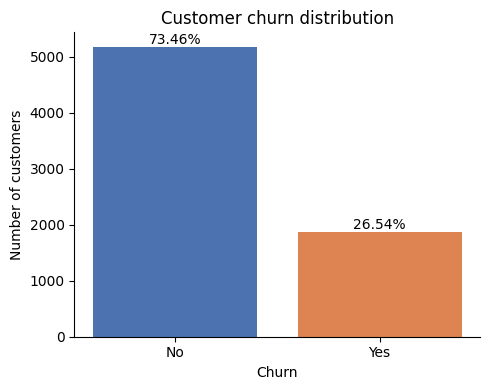

In [13]:
VISUALS_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(dist.index, dist["count"], color=["#4C72B0", "#DD8452"])
for bar, pct in zip(bars, dist["percentage"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50, f"{pct}%", ha="center")
ax.set_title("Customer churn distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "target_distribution.png", dpi=150)
plt.show()

**Observations**

- **26.54%** of customers churned (1,869) versus **73.46%** who stayed (5,174), roughly a 2.8 : 1 ratio. The dataset is **moderately imbalanced**.
- A model that always predicts "No churn" would already reach about 73% accuracy without detecting a single churner. **Accuracy alone is therefore misleading**, and models will be compared using Precision, Recall, F1-score and ROC-AUC.
- The train/test split will be **stratified** to keep this class proportion, and imbalance-handling techniques will be tested in Week 4.

---
# Week 2: Exploratory Data Analysis and Feature Engineering

## 5. Exploratory Data Analysis

Goal: understand **which customers churn and why**, using the cleaned dataset.

In [14]:
import seaborn as sns
from scipy.stats import chi2_contingency

from churn.config import FEATURES_DATA_PATH, ML_READY_DATA_PATH
from churn.features.engineering import ENGINEERED_FEATURES, add_features
from churn.features.preprocessing import (
    LOW_SIGNAL_FEATURES,
    NUMERIC_FEATURES,
    encode_features,
    scale_numeric,
    select_features,
    split_features_target,
)
from churn.visualization.eda import CHURN_COLORS, churn_rate_by, plot_churn_rate, save_fig

sns.set_theme(style="whitegrid")
NUMERIC_COLUMNS = ["tenure", "MonthlyCharges", "TotalCharges"]
overall_churn = df["Churn"].eq("Yes").mean() * 100

### 5.1 Descriptive statistics

In [15]:
df[NUMERIC_COLUMNS].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [16]:
df.groupby("Churn")[NUMERIC_COLUMNS].agg(["mean", "median"]).round(2)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [17]:
df.drop(columns="customerID").describe(include="object").T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,2,No,4072
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,2,No,5024
OnlineBackup,7043,2,No,4614
DeviceProtection,7043,2,No,4621


- Customers stay **32 months on average** (median 29), with a wide range from 0 to 72 months.
- Monthly charges go from **\$18.25 to \$118.75** (mean \$64.76). `TotalCharges` is right-skewed because it accumulates over time.
- Customers who churned have a **much lower median tenure (10 vs 38 months)** and a **higher median monthly charge (\$79.65 vs \$64.43)**.

### 5.2 Distribution of numerical variables

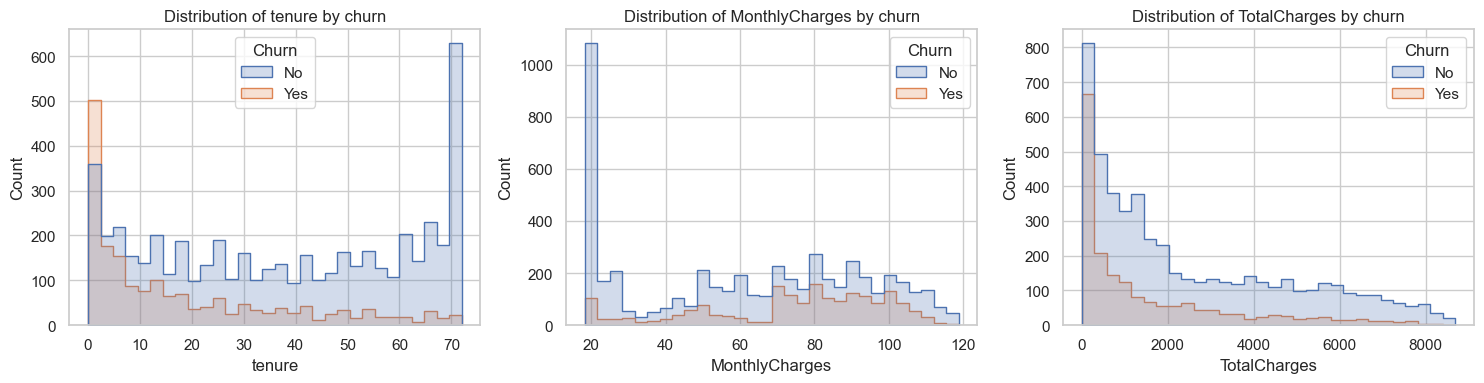

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_COLUMNS):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, palette=CHURN_COLORS, element="step", ax=ax)
    ax.set_title(f"Distribution of {col} by churn")
fig.tight_layout()
save_fig(fig, "numeric_distributions.png")
plt.show()

- **Tenure:** churners are concentrated in the first months, while non-churners have a second peak at 70+ months (long-term loyal customers).
- **MonthlyCharges:** the cheapest plans (about \$20) have very little churn; churn is more frequent above \$70.
- **TotalCharges:** churners are concentrated at low values, a direct consequence of their short tenure.

### 5.3 Outlier detection

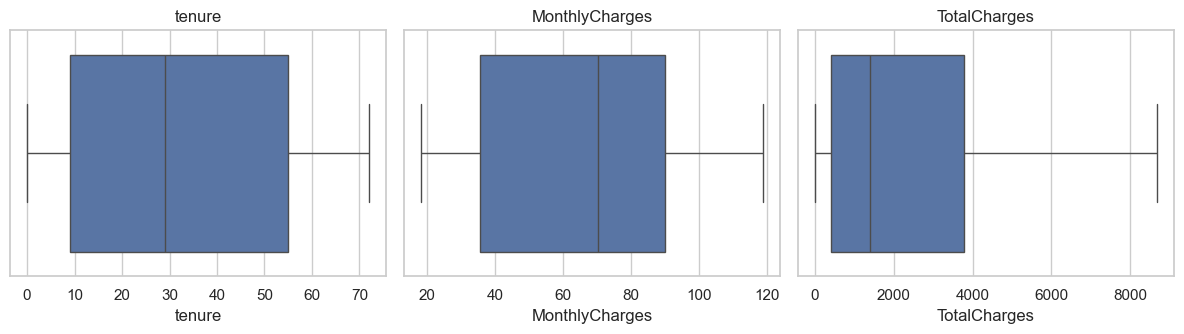

,outliers (IQR rule)
tenure,0
MonthlyCharges,0
TotalCharges,0


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, NUMERIC_COLUMNS):
    sns.boxplot(data=df, x=col, color="#4C72B0", ax=ax)
    ax.set_title(col)
fig.tight_layout()
save_fig(fig, "outliers_boxplots.png")
plt.show()

def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

df[NUMERIC_COLUMNS].apply(count_iqr_outliers).rename("outliers (IQR rule)").to_frame()

The IQR rule finds **no outliers** in any numerical variable, and every value is realistic (tenure between 0 and 72 months, charges within the plan price range). **No outlier handling is needed**, so no rows are removed.

### 5.4 Churn by contract, payment method, internet service and billing

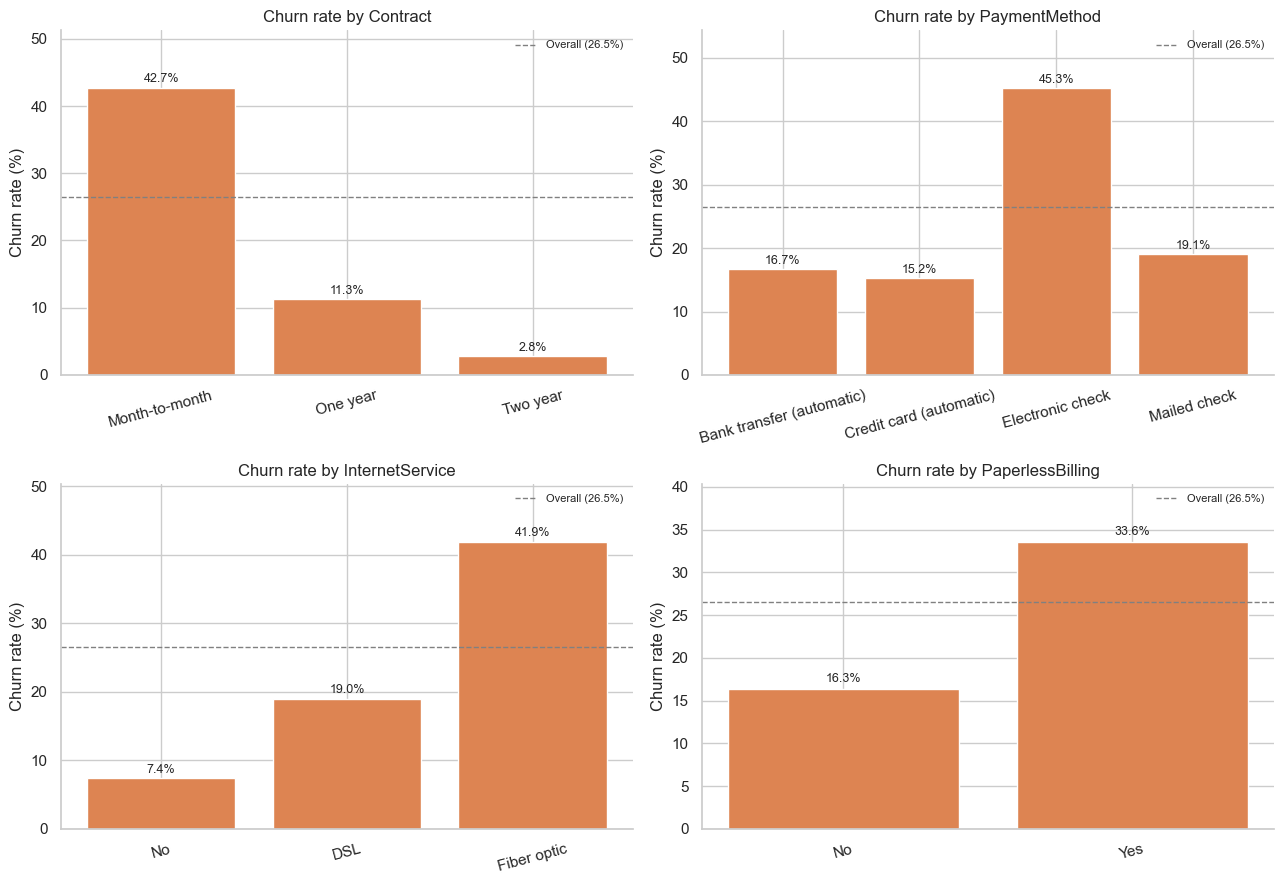

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_churn_rate(df, "Contract", ax=axes[0, 0], order=["Month-to-month", "One year", "Two year"])
plot_churn_rate(df, "PaymentMethod", ax=axes[0, 1])
plot_churn_rate(df, "InternetService", ax=axes[1, 0], order=["No", "DSL", "Fiber optic"])
plot_churn_rate(df, "PaperlessBilling", ax=axes[1, 1], order=["No", "Yes"])
fig.tight_layout()
save_fig(fig, "churn_analysis.png")
plt.show()

In [21]:
pd.concat(
    {col: churn_rate_by(df, col) for col in ["Contract", "PaymentMethod", "InternetService"]}
).rename_axis(["variable", "category"])

customers  churn_rate
variable        category                                        
Contract        Month-to-month                  3875       42.71
                One year                        1473       11.27
                Two year                        1695        2.83
PaymentMethod   Bank transfer (automatic)       1544       16.71
                Credit card (automatic)         1522       15.24
                Electronic check                2365       45.29
                Mailed check                    1612       19.11
InternetService DSL                             2421       18.96
                Fiber optic                     3096       41.89
                No                              1526        7.40

### 5.5 Churn by tenure and monthly charges

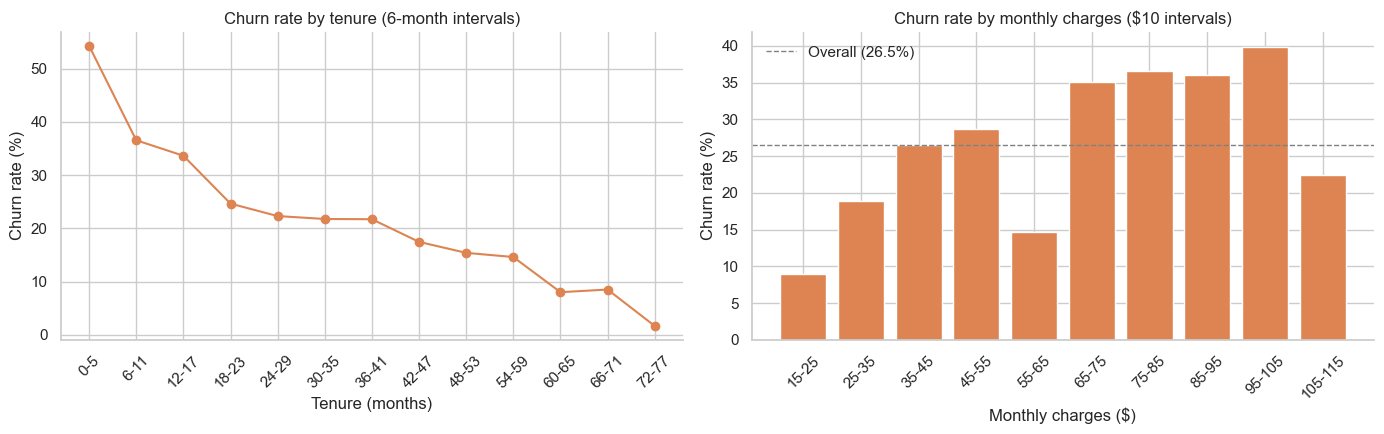

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

tenure_bins = pd.cut(df["tenure"], bins=range(-1, 79, 6))
tenure_rate = df.groupby(tenure_bins, observed=True)["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
axes[0].plot(range(len(tenure_rate)), tenure_rate.values, marker="o", color=CHURN_COLORS["Yes"])
axes[0].set_xticks(range(len(tenure_rate)))
axes[0].set_xticklabels([f"{int(i.left) + 1}-{int(i.right)}" for i in tenure_rate.index], rotation=45)
axes[0].set_title("Churn rate by tenure (6-month intervals)")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Churn rate (%)")

charge_bins = pd.cut(df["MonthlyCharges"], bins=range(15, 125, 10))
charge_rate = df.groupby(charge_bins, observed=True)["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
axes[1].bar(range(len(charge_rate)), charge_rate.values, color=CHURN_COLORS["Yes"])
axes[1].set_xticks(range(len(charge_rate)))
axes[1].set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in charge_rate.index], rotation=45)
axes[1].axhline(overall_churn, color="gray", linestyle="--", linewidth=1, label=f"Overall ({overall_churn:.1f}%)")
axes[1].set_title("Churn rate by monthly charges (\$10 intervals)")
axes[1].set_xlabel("Monthly charges (\$)")
axes[1].set_ylabel("Churn rate (%)")
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "churn_by_tenure_and_charges.png")
plt.show()

### 5.6 Churn by customer demographics

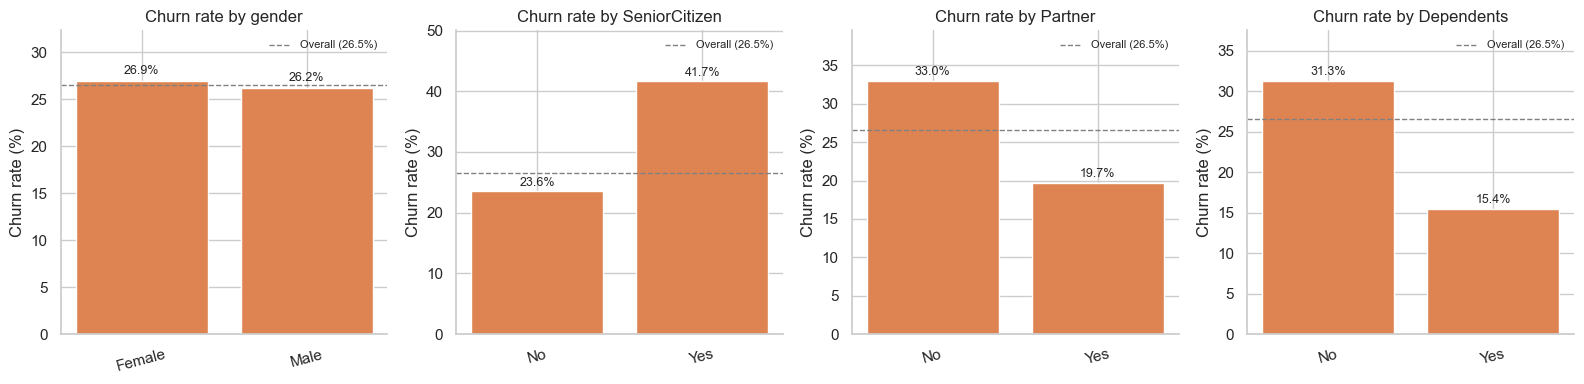

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    plot_churn_rate(df, col, ax=ax)
fig.tight_layout()
save_fig(fig, "churn_by_demographics.png")
plt.show()

### 5.7 Churn by subscribed services

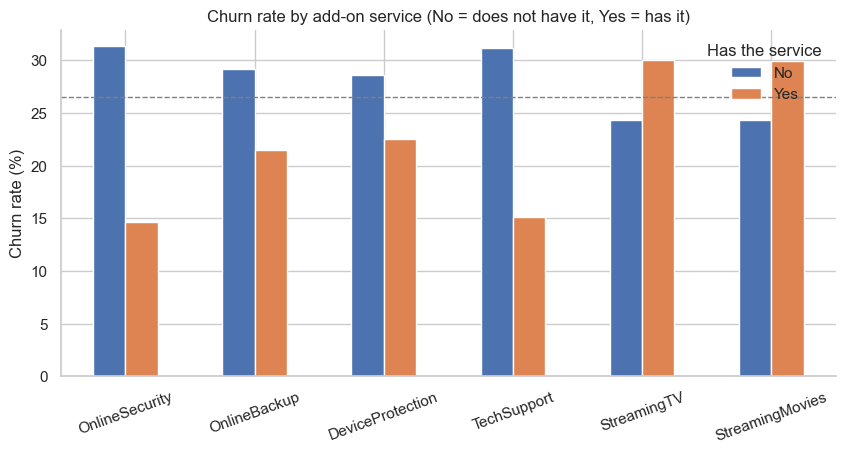

,No,Yes
OnlineSecurity,31.33,14.61
OnlineBackup,29.17,21.53
DeviceProtection,28.65,22.50
TechSupport,31.19,15.17
StreamingTV,24.33,30.07
StreamingMovies,24.38,29.94


In [24]:
service_columns = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
service_rates = pd.DataFrame(
    {col: churn_rate_by(df, col)["churn_rate"] for col in service_columns}
).T[["No", "Yes"]]

ax = service_rates.plot(kind="bar", figsize=(10, 4.5), color=[CHURN_COLORS["No"], CHURN_COLORS["Yes"]])
ax.axhline(overall_churn, color="gray", linestyle="--", linewidth=1)
ax.set_title("Churn rate by add-on service (No = does not have it, Yes = has it)")
ax.set_ylabel("Churn rate (%)")
ax.tick_params(axis="x", labelrotation=20)
ax.legend(title="Has the service", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig(ax.figure, "churn_by_services.png")
plt.show()
service_rates

### 5.8 Correlations

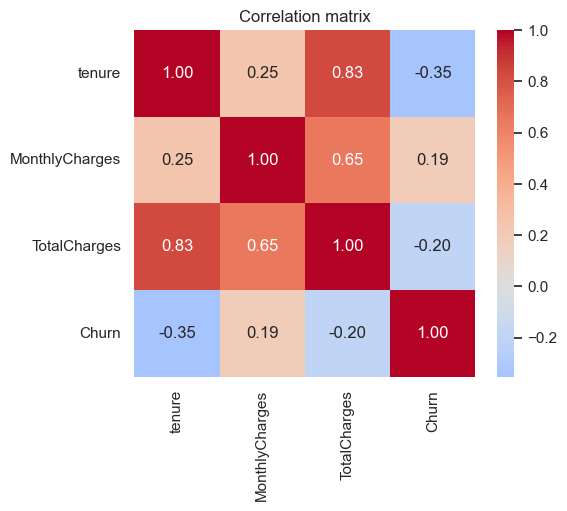

In [25]:
corr_df = df[NUMERIC_COLUMNS].assign(Churn=df["Churn"].eq("Yes").astype(int))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
save_fig(fig, "correlation_heatmap.png")
plt.show()

- `tenure` and `TotalCharges` are strongly correlated (**0.83**), as expected since the total is roughly tenure x monthly charge. This redundancy matters for Logistic Regression.
- `tenure` has the strongest (negative) relation with churn (**-0.35**); `MonthlyCharges` has a weaker positive one (**0.19**).

### 5.9 Key insights

1. **Contract type is the strongest driver.** Month-to-month customers churn **42.7%**, versus 11.3% (one year) and only 2.8% (two year).
2. **New customers churn the most.** Churn is 47.4% in the first year and falls steadily with tenure. Churners have a median tenure of 10 months versus 38 for loyal customers.
3. **Higher bills are linked to more churn.** Customers paying \$70-\$90 per month churn about 38%, versus about 11% for those paying under \$35.
4. **Payment method matters.** Electronic check users churn **45.3%**, around three times more than customers on automatic payments (bank transfer 16.7%, credit card 15.2%).
5. **Fiber optic customers churn far more than the rest.** 41.9% versus 19.0% for DSL and 7.4% for customers without internet. Fiber is also the most expensive plan, which points to a price or quality problem.
6. **Support and security services protect against churn.** Customers with Online Security or Tech Support churn about 15%, versus about 31% for those without them.
7. **Demographics:** senior citizens (41.7% vs 23.6%) and customers without partner (33.0% vs 19.7%) or dependents (31.3% vs 15.5%) churn more, while **gender has no effect** (26.9% vs 26.2%).
8. **Paperless billing** is associated with higher churn (33.6% vs 16.3%).

## 6. Feature Engineering

New features created from the cleaned data (implemented in `src/churn/features/engineering.py` and documented in [`docs/feature_engineering.md`](../docs/feature_engineering.md)):

| New feature | How it was created | Why it may help predict churn |
|---|---|---|
| `tenure_group` | `tenure` binned into 0-12, 13-24, 25-48 and 49-72 months | Churn follows a clear lifecycle: it is highest in the first year. Groups capture this non-linear effect. |
| `num_services` | Count of subscribed services: phone, multiple lines, internet and the six add-ons | Customers with more services are more tied to the company, but also pay more. |
| `num_protection_services` | Count of `OnlineSecurity`, `OnlineBackup`, `DeviceProtection` and `TechSupport` | Protection and support services showed lower churn in the EDA. |
| `has_streaming` | `Yes` if the customer has `StreamingTV` or `StreamingMovies` | Summarizes the entertainment services in a single indicator. |
| `spending_category` | `MonthlyCharges` binned into Low (up to \$35), Medium (\$35-\$70) and High (above \$70) | Churn rises with the monthly bill, and bands capture it as customer value groups. |
| `auto_payment` | `Yes` if the payment method is bank transfer or credit card (automatic) | Automatic payment needs no monthly action, so those customers churn much less. |
| `avg_monthly_spend` | `TotalCharges / tenure` (current `MonthlyCharges` when tenure is 0) | Reveals customers whose current bill differs from what they historically paid. |

In [26]:
df_fe = add_features(df)
df_fe[["customerID", "tenure", "MonthlyCharges", *ENGINEERED_FEATURES]].head(8)

,customerID,tenure,MonthlyCharges,tenure_group,num_services,num_protection_services,has_streaming,spending_category,auto_payment,avg_monthly_spend
0,7590-VHVEG,1,29.85,0-12 months,2,1,No,Low,No,29.85
1,5575-GNVDE,34,56.95,25-48 months,4,2,No,Medium,No,55.57
2,3668-QPYBK,2,53.85,0-12 months,4,2,No,Medium,No,54.08
3,7795-CFOCW,45,42.30,25-48 months,4,3,No,Medium,Yes,40.91
4,9237-HQITU,2,70.70,0-12 months,2,0,No,High,No,75.82
5,9305-CDSKC,8,99.65,0-12 months,6,1,Yes,High,No,102.56
6,1452-KIOVK,22,89.10,13-24 months,5,1,Yes,High,Yes,88.61
7,6713-OKOMC,10,29.75,0-12 months,2,1,No,Low,No,30.19


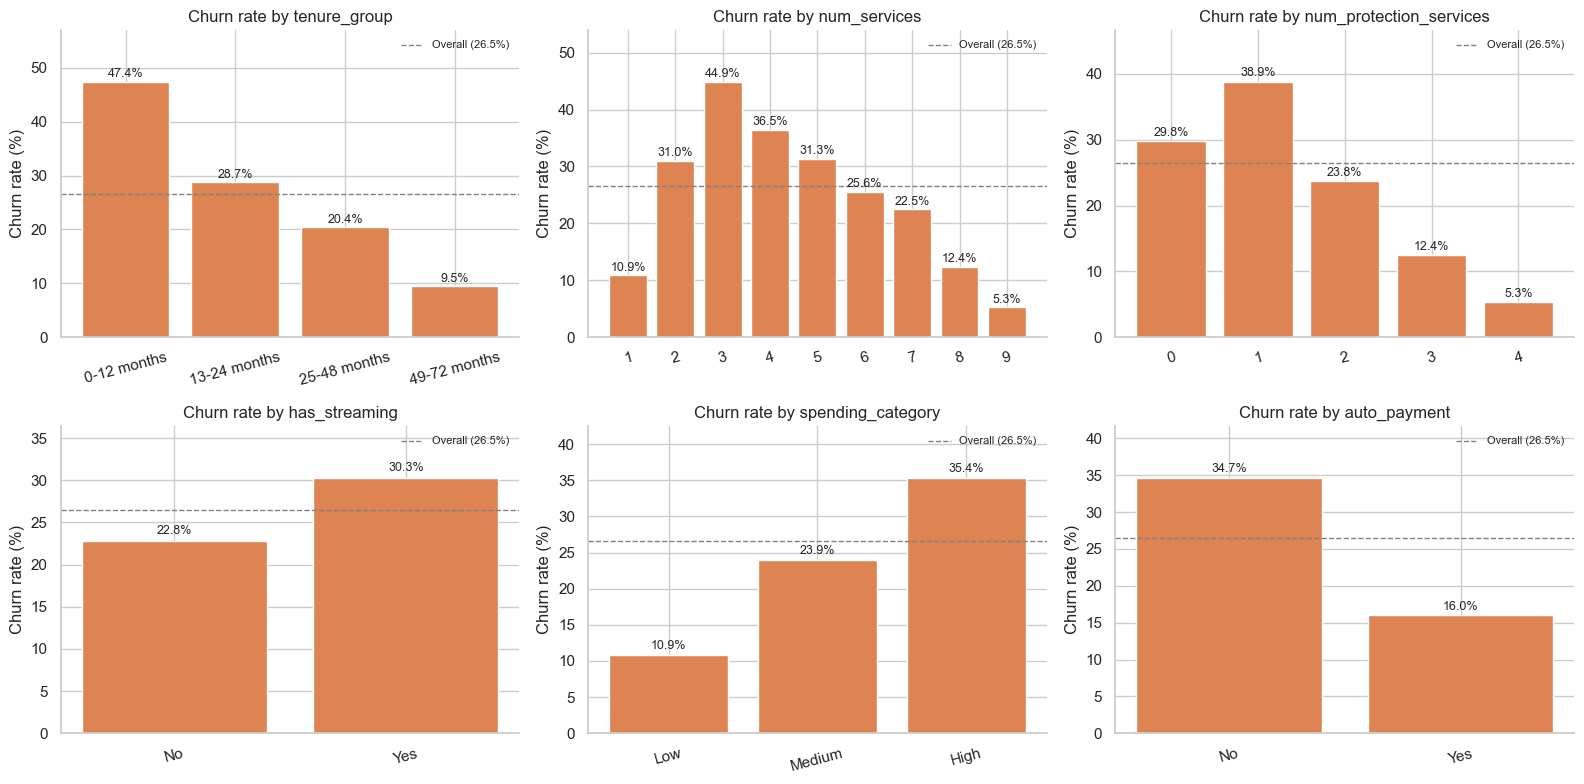

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
plot_churn_rate(df_fe, "tenure_group", ax=axes[0, 0])
plot_churn_rate(df_fe, "num_services", ax=axes[0, 1])
plot_churn_rate(df_fe, "num_protection_services", ax=axes[0, 2])
plot_churn_rate(df_fe, "has_streaming", ax=axes[1, 0], order=["No", "Yes"])
plot_churn_rate(df_fe, "spending_category", ax=axes[1, 1], order=["Low", "Medium", "High"])
plot_churn_rate(df_fe, "auto_payment", ax=axes[1, 2], order=["No", "Yes"])
fig.tight_layout()
save_fig(fig, "engineered_features.png")
plt.show()

- `tenure_group`: churn drops from **47.4%** (0-12 months) to **9.5%** (49-72 months).
- `num_protection_services`: churn falls from 38.9% (1 service) to **5.3%** (all 4), confirming that these services keep customers.
- `spending_category`: **High** spenders churn 35.4% versus 10.9% for **Low** spenders.
- `auto_payment`: customers without automatic payment churn **34.7%** versus 16.0% with it.
- `num_services` is not linear: customers with a single service (basically phone only) churn little (10.9%), churn peaks at 3 services (44.9%, typically fiber without add-ons) and falls again with many services (5.3% with 9).

## 7. Data Preprocessing

### 7.1 Feature selection

A chi-square test measures whether each categorical feature is related to churn. The null hypothesis is that the feature and churn are independent; a p-value above 0.05 means no evidence of a relation.

In [28]:
categorical_cols = df_fe.select_dtypes(include="object").columns.drop(["customerID", "Churn"])
chi2_results = pd.DataFrame(
    {col: chi2_contingency(pd.crosstab(df_fe[col], df_fe["Churn"]))[1] for col in categorical_cols},
    index=["p_value"],
).T.sort_values("p_value")
chi2_results["related_to_churn"] = chi2_results["p_value"] < 0.05
chi2_results.round(4)

,p_value,related_to_churn
Contract,0.0000,True
tenure_group,0.0000,True
InternetService,0.0000,True
PaymentMethod,0.0000,True
spending_category,0.0000,True
auto_payment,0.0000,True
PaperlessBilling,0.0000,True
OnlineSecurity,0.0000,True
TechSupport,0.0000,True
Dependents,0.0000,True


Only **`gender`** (p = 0.49) and **`PhoneService`** (p = 0.34) show no relation with churn, so they are **dropped**. Other decisions:

- `customerID` is an identifier, not a predictor: **dropped**.
- `TotalCharges` is highly correlated with `tenure` (0.83) but it is **kept**, since tree-based models are not affected and the effect on Logistic Regression will be checked in Week 3.
- The original `tenure` and `MonthlyCharges` are kept next to their engineered groups because each carries different information (exact value vs. band).

In [29]:
assert set(chi2_results.index[~chi2_results["related_to_churn"]]) == set(LOW_SIGNAL_FEATURES)

df_selected = select_features(df_fe)
print(f"Features kept: {df_selected.shape[1] - 1} (plus the target)")

Features kept: 24 (plus the target)


### 7.2 Encoding categorical variables

- **Binary columns (Yes/No)** and the target become `1/0`.
- **Multi-category columns** (`InternetService`, `Contract`, `PaymentMethod`, `tenure_group`, `spending_category`) are one-hot encoded, dropping the first level to avoid redundant columns.

In [30]:
df_ml = encode_features(df_selected)
print(f"Shape: {df_ml.shape} | missing values: {df_ml.isna().sum().sum()}")
df_ml.dtypes.value_counts()

Shape: (7043, 32) | missing values: 0


int64      29
float64     3
Name: count, dtype: int64

### 7.3 Scaling numerical features

Numerical variables have very different ranges (`num_protection_services` from 0 to 4, `TotalCharges` up to 8,685). Distance- and gradient-based models such as Logistic Regression and KNN need standardized features, while tree-based models do not.

To avoid **data leakage**, the scaler must be **fitted on the training set only**. Because the train/test split is done in Week 3, the saved dataset is left **unscaled** and `scale_numeric()` (in `src/churn/features/preprocessing.py`) is applied after splitting. The next cell is only a demonstration that it works:

In [31]:
X, y = split_features_target(df_ml)
X_demo_train, X_demo_test, _ = scale_numeric(X.iloc[:5000], X.iloc[5000:])
X_demo_train[NUMERIC_FEATURES].agg(["mean", "std"]).round(2)

,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,num_services,num_protection_services
mean,0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


### 7.4 Separate features and target, and save the machine-learning-ready dataset

In [32]:
df_fe.to_csv(FEATURES_DATA_PATH, index=False)
df_ml.to_csv(ML_READY_DATA_PATH, index=False)

print(f"Feature-engineered dataset: {df_fe.shape[0]:,} rows x {df_fe.shape[1]} columns -> {FEATURES_DATA_PATH.name}")
print(f"ML-ready dataset:           {df_ml.shape[0]:,} rows x {df_ml.shape[1]} columns -> {ML_READY_DATA_PATH.name}")
print(f"\nX: {X.shape} | y: {y.shape} | churn rate in y: {y.mean():.2%}")
print(f"\nFeatures used for modeling ({X.shape[1]}):")
print(list(X.columns))

Feature-engineered dataset: 7,043 rows x 28 columns -> telco_churn_features.csv
ML-ready dataset:           7,043 rows x 32 columns -> telco_churn_ml_ready.csv

X: (7043, 31) | y: (7043,) | churn rate in y: 26.54%

Features used for modeling (31):
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'num_services', 'num_protection_services', 'has_streaming', 'auto_payment', 'avg_monthly_spend', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure_group_13-24 months', 'tenure_group_25-48 months', 'tenure_group_49-72 months', 'spending_category_Low', 'spending_category_Medium']


**Week 2 summary**

- 10+ visualizations saved in `visuals/` and 8 documented insights.
- 7 engineered features and 2 low-signal features removed.
- `telco_churn_ml_ready.csv`: fully numeric, no missing values, ready for the train/test split.

---
_Next: Week 3, train/test split and classification models (Logistic Regression, Decision Tree, Random Forest, XGBoost)._